# CO₂ sin O₂ — `theta_full` fijo

Se retiran el estado de oxígeno disuelto, su ecuación de consumo y el factor que reducía la fuente de CO₂. Se conserva la formulación principal de `co2_lab016_021_recalibration_v3`: cinética química, condiciones iniciales, pulsos, activación por azúcar consumida (2–10 g/L), respuesta a nutrición, reservorio y operador de observación. No se utiliza la capa de Zenteno.

`theta_full` permanece fijo. Z1 ajusta solo la ganancia; Z2 ajusta liberación, escala de solubilidad efectiva y ganancia. El entrenamiento principal usa LAB019–021 y la validación LAB016–018. Se incluyen el ajuste descriptivo con los seis LAB y la transferencia inversa para mantener la comparación con v3. La validación no selecciona la estructura, el filtro ni los parámetros.

Las figuras muestran curvas completas, muestras químicas reservadas y los pulsos de nutrición. Las figuras quedan dentro del EXECUTED; las tablas se guardan en `co2_woO2_artifacts`.

## Ecuaciones y parámetros

La química integra únicamente $X,N,G,F,E$, proyectando las mismas ecuaciones compartidas y conservando la pérdida de biomasa viable por muerte. Biomasa muerta y glicerol no se integran ni se representan. Para construir la respuesta histórica a nutrición se calculan las trayectorias con pulsos ($q_n$) y sin ellos ($q_0$):

$$q_{n,0}=\frac{44.01}{46.07}(\beta_G+\beta_F)X_{n,0},\qquad
q_{\rm prod}=a(S_0-S)M(t)\max\{[1+(b-1)r]q_0+r(q_n-q_0),0\}.$$

El operador $a$ es un smoothstep entre 2 y 10 g/L de azúcar consumida; $r$ es la rampa nutricional, $b$ la ganancia de actividad y $M$ el transitorio heredado. Se conserva su posible cancelación postnutrición para aislar el cambio de O₂.

$$\dot C_d=q_{\rm prod}-q_{\rm gas},\qquad
q_{\rm gas}=k C_d\left(0.05+0.95\frac{C_d}{C_d+C^\star(t)}\right),\qquad C_d(0)=0.$$
$$C^\star(t)=s\,1.69\exp[-0.032(T-20)]\exp(0.0016E)\exp[-0.0012(G+F)].$$

$C^\star$ modula la liberación; no impone retención total hasta saturación. La señal predicha es la ganancia por el caudal, pasada por el mismo Butterworth offline que las observaciones. No hay producción respiratoria añadida ni estado o factor de O₂.

| Ajuste | Parámetros libres | Límites |
|---|---|---|
| Z1 | `matrix_gain` | 0.1–20 |
| Z2 | `kCO2_release_h`, `CO2sat_scale`, `matrix_gain` | 0.03–25 h⁻¹; 0.35–2.5; 0.1–20 |

El filtrado, el cambio de hora chileno, los horizontes y la pérdida son los de v3: Hampel centrado de 120 s; Butterworth orden 3 adelante–atrás, τ=30 min; T con mediana 20 min y media 45 min; medianas CO₂ de 10 min. Sin exclusiones por nutrición. Cada LAB pesa igual; bajo 0.05 g/L/h se usa una penalización unilateral. Los RMSE se calculan sin censura. Las muestras químicas no entran al ajuste de CO₂.

In [1]:
from pathlib import Path
from datetime import datetime
import ast,json,sys,time,hashlib
from dataclasses import replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import display,Markdown,JSON
%matplotlib inline
ROOT=Path.cwd().resolve()
while ROOT.name!='pyomo-doe' and ROOT.parent!=ROOT:ROOT=ROOT.parent
assert ROOT.name=='pyomo-doe'
assert Path(sys.prefix).name.lower()=='fermentation',sys.executable
FM=ROOT/'fermentation_model'
sys.path.insert(0,str(FM))
from shared import run_new_must_glycerol_estimability_doe as base
ND=FM/'laboratory_2026/notebooks/co2_reformulation'
OUT=ND/'co2_woO2_artifacts';OUT.mkdir(exist_ok=True)
START=time.perf_counter()
Y_CO2_E=44.01/46.07
GAS_NAMES=('kCO2_release_h','CO2sat_scale','matrix_gain')
GAS_BOUNDS=((.03,25.),(.35,2.5),(.1,20.))
print('Python:',sys.executable)

Python: D:\anaconda3\envs\fermentation\python.exe


## Implementación local
Las funciones siguientes se incluyen para que SOURCE sea ejecutable sin importar código de otro notebook ni modificar módulos compartidos.

In [2]:
def sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()

def local_lfs_content(path, root):
    """Read an already cached LFS object without hydrating/mutating the worktree."""
    with open(path, 'rb') as handle:
        head = handle.read(200)
    if not head.startswith(b'version https://git-lfs.github.com/spec/v1'):
        return path
    lines = head.decode('ascii').splitlines()
    oid = next((line.split('sha256:', 1)[1] for line in lines if line.startswith('oid ')))
    content = Path(root) / '.git/lfs/objects' / oid[:2] / oid[2:4] / oid
    if not content.is_file():
        raise FileNotFoundError(f'Required LFS object is absent locally: {oid}')
    assert sha256(content) == oid
    return content

def release_forward(c, p, max_step=None):
    """Conservative implicit reservoir, identical to v2 (positive root)."""
    k, scale, gain = (p[n] for n in GAS_NAMES)
    source, dt = (c['source'], c['dt'])
    sat = c['sat_base'] * scale
    cd, out = (np.zeros(len(source)), np.zeros(len(source)))
    for i in range(1, len(source)):
        subdivisions = 1 if max_step is None else int(np.ceil(dt[i - 1] / max_step))
        step = dt[i - 1] / subdivisions
        inventory, released = (cd[i - 1], 0.0)
        for _ in range(subdivisions):
            a = inventory + step * source[i - 1]
            aa = 1.0 + step * k
            b = sat[i] * (1.0 + 0.05 * step * k) - a
            root = np.sqrt(b * b + 4.0 * aa * a * sat[i])
            new = 2.0 * a * sat[i] / (root + b) if b >= 0.0 else (root - b) / (2.0 * aa)
            released += a - new
            inventory = new
        cd[i], out[i] = (inventory, released / dt[i - 1])
    return (gain * out, cd, out)


CORE_STATES=('X','N','G','F','E')
CORE_INDEX=[base.STATE_NAMES.index(s) for s in CORE_STATES]

def integrate_core(batch,theta,time):
    """Five active chemical states; identical shared RHS projection, exact N jumps."""
    def rhs(t,y):
        full=np.zeros(len(base.STATE_NAMES))
        full[CORE_INDEX]=y
        return np.asarray(base.rhs(t,full,theta,batch))[CORE_INDEX]
    time=np.asarray(time,float)
    state=np.array([batch.initials[s] for s in CORE_STATES])
    events={}
    for t,dose in batch.pulses['N']:
        if time[0]<=t<=time[-1]:events[t]=events.get(t,0.)+dose
    records={float(time[0]):state.copy()}
    current=float(time[0])
    if current in events:state[1]+=events[current]
    for boundary in sorted({float(time[-1]),*[t for t in events if t>current]}):
        requested=time[(time>current)&(time<=boundary)]
        sol=solve_ivp(rhs,(current,boundary),state,t_eval=np.unique(np.r_[requested,boundary]),
                      method='LSODA',rtol=2e-9,atol=2e-11,max_step=.5)
        assert sol.success,sol.message
        records.update({float(t):y.copy() for t,y in zip(sol.t,sol.y.T)})
        state=sol.y[:,-1].copy();current=boundary
        if current in events:state[1]+=events[current]
    values=np.vstack([records[float(t)] for t in time])
    assert np.isfinite(values).all() and values.min()>-1e-7
    frame=pd.DataFrame(np.maximum(values,0.),index=time,columns=CORE_STATES)
    frame['GF']=frame.G+frame.F
    return frame

def production(theta,batch,core):
    return np.array([Y_CO2_E*(k['beta_g']+k['beta_f'])*row.X
        for t,row in core.iterrows()
        for k in [base.kinetic_terms(theta,base.temperature_at(batch,t),row.X,row.N,row.G,row.F,row.E)]])

class Search:
    def __init__(self,root):
        self.root=Path(root);self.fm=self.root/'fermentation_model';self.lab=self.fm/'laboratory_2026'
        self.base=base
        self.v2=self.lab/'results/co2_lab016_021_recalibration_v2'
        manifest_path=self.v2/'manifest.json'
        self.manifest=json.loads(manifest_path.read_text(encoding='utf-8'))
        theta_path=self.lab/'results/estimability_historical_natural/theta_natural_full.csv'
        table=pd.read_csv(theta_path).set_index('parameter').theta.astype(float).to_dict()
        self.thetas={'theta_full':{p:table[p] for p in base.FULL17}}
        assert self.thetas['theta_full']==self.manifest['theta_fixed']['theta_full']
        self.theta_snapshot=self.thetas['theta_full'].copy()
        self.old={k:v for k,v in self.manifest['old_gas_start'].items() if not k.startswith('O2_')}
        self.old.update(activation_start_g_l=2.,activation_width_g_l=8.)
        self.inputs=[manifest_path,theta_path,Path(base.__file__)]
        def read(name):
            p=self.v2/name;self.inputs.append(p);return pd.read_csv(p)
        self.initials=read('initial_conditions.csv').set_index('lab')
        self.obs=read('observations.csv')
        self.chem=read('chemistry_observations_corrected_YAN.csv')
        self.density=read('density_sugar_comparison/density_sugar_points.csv')
        self.biomass=read('biomass_lab016_018.csv')
        self.previous_chemistry=read('chemistry_trajectories.csv')
        self.protected={str(p.relative_to(self.root)):sha256(p) for p in self.inputs}
        self.cores,self.cache,self.theta_by_case={},{},{}

    @staticmethod
    def histories(time,events,p):
        ramp=np.clip((time-events[0][0])/p['pulse_t_rise_h'],0.,1.) if events else np.zeros(len(time))
        mult=np.ones(len(time));tr,td=p['tau_rise_h'],p['tau_decay_h']
        up=tr*np.log1p(td/tr);peak=-np.expm1(-up/tr)*np.exp(-up/td)
        for event,dose in events:
            u=np.maximum(time-event,0.)
            mult+=p['A']*dose/p['N_ref_g_l']*(-np.expm1(-u/tr))*np.exp(-u/td)/peak
        return ramp,mult

    def prepare(self,name,theta,labs):
        assert name=='theta_full' and theta==self.theta_snapshot
        self.theta_by_case[name]=theta.copy()
        for lab in labs:
            bt=self.batches[lab]
            cr=integrate_core(bt,theta,bt.time)
            cr0=integrate_core(replace(bt,pulses={**bt.pulses,'N':()}),theta,bt.time)
            time=bt.time;qn,q0=production(theta,bt,cr),production(theta,bt,cr0)
            ramp,mult=self.histories(time,bt.pulses['N'],self.old)
            consumed=cr.GF.iloc[0]-cr.GF.to_numpy()
            z=np.clip((consumed-2.)/8.,0.,1.);gate=z*z*(3.-2.*z)
            activity=1.+(self.old['pulse_activity_gain']-1.)*ramp
            # Sole structural change from the principal v3 source: no O2 factor/state.
            source=gate*mult*np.maximum(activity*q0+ramp*(qn-q0),0.)
            sat_base=1.69*np.exp(-.032*(bt.temperature_c-20.))*np.exp(.0016*cr.E.to_numpy())*np.exp(-.0012*cr.GF.to_numpy())
            d=self.obs[self.obs.lab.eq(lab)].sort_values('t_h')
            idx=np.searchsorted(time,d.t_h.to_numpy())-1
            w=(d.t_h.to_numpy()-time[idx])/(time[idx+1]-time[idx])
            self.cores[name,lab]=cr
            self.cache[name,lab]=dict(time=time,dt=np.diff(time),source=source,sat_base=sat_base,
                qn=qn,q0=q0,ramp=ramp,multiplier=mult,gate=gate,obs=d,idx=idx,w=w,
                events=bt.pulses['N'],core=cr,sugar_consumed=consumed)

    def source_cache(self,case,lab,p,mode='woO2'):
        assert mode=='woO2'
        return self.cache[case,lab]

    def verify_protected(self):
        assert self.thetas['theta_full']==self.theta_snapshot
        assert all(sha256(self.root/p)==h for p,h in self.protected.items())
        return len(self.protected)

In [3]:
"""Offline, zero-phase preprocessing and CO2 recalibration for LAB016--021.

Only local diagnostic artifacts are written by the accompanying notebook.
GUI scripts are parsed for parameters; hardware/UI code is never imported.
"""
import ast
import json
from dataclasses import replace
from pathlib import Path
import numpy as np
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view
from scipy import signal
from scipy.optimize import least_squares, minimize_scalar
LABS = tuple((f'LAB{i:03}' for i in range(16, 22)))
FILTERS = {'offline_20min': 1200.0, 'offline_30min': 1800.0, 'offline_40min': 2400.0}
PRIMARY = 'offline_30min'
OBS_STEP_H = 1.0 / 6.0
LOD = 0.05
QUIET = 0.02
FACTOR = 44.0095 * 60.0 * 0.74 / (1000.0 * 24.16 * 2.0)
LOCAL_ZONE = 'America/Santiago'

def local_to_utc(values):
    """Interpret logger/worksheet civil times, rejecting ambiguous/invalid times."""
    return pd.DatetimeIndex(pd.to_datetime(values)).tz_localize(LOCAL_ZONE, ambiguous='raise', nonexistent='raise').tz_convert('UTC')

def elapsed_civil_hours(hours, origin_local):
    """Convert legacy naive-clock offsets, not actual elapsed durations, to UTC."""
    wall = origin_local + pd.to_timedelta(np.asarray(hours, float), unit='h')
    return (local_to_utc(wall) - local_to_utc([origin_local])[0]).total_seconds() / 3600.0

def gui_constants(path):
    wanted = {'W_SPIKE_SECONDS', 'K', 'MIN_ABS_SPIKE', 'TAU_SECONDS', 'BUTTER_ORDER'}
    constants = {}
    for node in ast.parse(Path(path).read_text(encoding='utf-8-sig')).body:
        if isinstance(node, ast.Assign):
            for target in node.targets:
                if isinstance(target, ast.Name) and target.id in wanted:
                    constants[target.id] = ast.literal_eval(node.value)
    assert set(constants) == wanted, constants
    return constants

def centered_hampel(values, dt_s, window_s=120.0, k=3.5, floor=0.5):
    """Exact median/MAD of the same centered odd window, reflection at edges."""
    x = np.asarray(values, float)
    assert np.isfinite(x).all()
    half = max(1, int(round(window_s / (2.0 * dt_s))))
    padded = np.pad(x, (half, half), mode='reflect')
    windows = sliding_window_view(padded, 2 * half + 1)
    med = np.median(windows, axis=1)
    mad = np.median(abs(windows - med[:, None]), axis=1)
    flag = abs(x - med) > np.maximum(k * 1.4826 * mad, floor)
    return (np.where(flag, med, x), flag)

def runs(mask):
    edges = np.diff(np.r_[False, np.asarray(mask, bool), False].astype(int))
    return list(zip(np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)))

def fill_short_gaps(series, max_samples):
    result = series.copy()
    candidate = series.interpolate(method='time', limit_area='inside')
    for a, b in runs(series.isna().to_numpy()):
        if b - a <= max_samples and a > 0 and (b < len(series)):
            result.iloc[a:b] = candidate.iloc[a:b]
    return result

def butter_sos(tau_s, dt_s, order=3):
    cutoff = 1.0 / (2.0 * np.pi * tau_s)
    return signal.butter(order, cutoff, fs=1.0 / dt_s, output='sos')

def zero_phase(values, tau_s, dt_s):
    padlen = min(int(np.ceil(6.0 * tau_s / dt_s)), len(values) - 2)
    assert padlen > 12 and len(values) > 24
    return signal.sosfiltfilt(butter_sos(tau_s, dt_s), values, padtype='odd', padlen=padlen)

def read_window(path, root, columns, start, end=None):
    content = local_lfs_content(path, root)
    pieces = []
    for chunk in pd.read_csv(content, usecols=columns, chunksize=400000, low_memory=False):
        stamp = pd.to_datetime(chunk.timestamp, errors='coerce')
        keep = stamp.ge(start)
        if end is not None:
            keep &= stamp.le(end)
        if keep.any():
            part = chunk.loc[keep].copy()
            part['timestamp'] = stamp[keep]
            pieces.append(part)
    if not pieces:
        raise ValueError(f'No data in requested window: {path}')
    return (pd.concat(pieces, ignore_index=True), content)

def old_artifact_windows(raw, temp, t0):
    """Same raw excursion rule and 90-min conservative recovery used by v2."""
    state = pd.to_numeric(temp.nutricion_activa, errors='raise').astype(int)
    rising = np.flatnonzero((state.eq(1) & ~state.shift(fill_value=0).eq(1)).to_numpy())
    falling = np.flatnonzero((state.eq(0) & state.shift(fill_value=0).eq(1)).to_numpy())
    raw = raw.sort_values('timestamp')
    rtime = (raw.timestamp - t0).dt.total_seconds().to_numpy() / 3600.0
    values = raw.flow_sccm.to_numpy(float)
    rows = []
    for a in rising:
        after = falling[falling > a]
        begin = (temp.timestamp.iloc[a] - t0).total_seconds() / 3600.0
        finish = (temp.timestamp.iloc[after[0]] - t0).total_seconds() / 3600.0 if len(after) else (temp.timestamp.iloc[-1] - t0).total_seconds() / 3600.0
        pre = values[(rtime >= begin - 1.0 / 3.0) & (rtime < begin)]
        event_idx = np.flatnonzero((rtime >= begin) & (rtime <= finish + 1.0 / 30.0))
        if len(pre) < 3 or not len(event_idx):
            continue
        center = np.median(pre)
        threshold = max(3.5 * 1.4826 * np.median(abs(pre - center)), 0.5)
        crossed = event_idx[abs(values[event_idx] - center) > threshold]
        if len(crossed):
            rows.append(dict(start_h=float(rtime[crossed[0]]), end_h=float(finish + 1.5), pump_start_h=begin, pump_end_h=finish, raw_threshold_sccm=threshold))
    return rows

class CO2WithoutOxygen(Search):

    def __init__(self, root):
        super().__init__(root)
        self.v2_initials = self.initials.copy()
        self.v2_obs = self.obs.copy()
        self.gui_paths = [self.fm / 'context/codigo_GUI' / name for name in ('NEW_GUI_filtrado_vFINAL.py', 'NEW_GUI_filtrado_vCTORREALBA_EZO_USB.py')]
        self.gui = gui_constants(self.gui_paths[0])
        assert self.gui == gui_constants(self.gui_paths[1])
        assert self.gui == dict(W_SPIKE_SECONDS=120.0, K=3.5, MIN_ABS_SPIKE=0.5, TAU_SECONDS=1200.0, BUTTER_ORDER=3)
        self.raw_co2, self.raw_temperature, self.t0, self.artifacts = ({}, {}, {}, {})
        self.dense, self.temperature, self.observations = ({}, {}, {})
        self.filter_audit, self.coverage_rows, self.temp_audit = ([], [], [])
        self.fit_runs, self.fit_table, self.v3_fits = ([], [], {})
        self.saved_core_contexts = {}
        self.clock_audit, self.elapsed_audit, self.nutrition_events = ([], [], [])
        old_dir = self.fm / 'data/mem2026/LAB016-018'
        book_path = old_dir / 'LAB016-018-offline-measurements.xlsx'
        sheet = pd.read_excel(book_path, sheet_name='CondicionesIniciales').set_index('CodigoLab')
        recent_dir = self.fm / 'data/mem2026/LAB019-021'
        recent_t0 = pd.Timestamp('2026-09-21 17:00:00')
        recent_co2_path = recent_dir / 'backup_global_co2_completo.csv'
        recent_temp_path = recent_dir / 'backup_global_temperatura_completo.csv'
        recent_co2, cpath = read_window(recent_co2_path, self.root, ['timestamp', 'fermentador', 'flow_sccm', 'flow_filt_sccm', 'status'], recent_t0 - pd.Timedelta(hours=6))
        recent_temp, tpath = read_window(recent_temp_path, self.root, ['timestamp', 'fermentador', 'T', 'SP', 'nutricion_activa'], recent_t0 - pd.Timedelta(hours=6))
        self.extra_inputs = self.gui_paths + [recent_co2_path, recent_temp_path, cpath, tpath, self.lab / 'notebooks/diagnostics/lab019_021_co2_onset_effective_model_test.ipynb', self.lab / 'notebooks/diagnostics/lab019_021_co2_onset_effective_model_test.executed.ipynb']
        for i, lab in enumerate(LABS):
            fermenter = f'F{i % 3 + 1}'
            if i < 3:
                row = sheet.loc[lab]
                clock = row.Hora if hasattr(row.Hora, 'hour') else pd.to_datetime(str(row.Hora)).time()
                t0 = pd.Timestamp.combine(pd.Timestamp(row.Fecha).date(), clock)
                raw_path = old_dir / f'CO2_F{i + 1}_{lab}.csv'
                filt_path = old_dir / f'CO2_FILT_F{i + 1}_{lab}.csv'
                temp_path = old_dir / {0: 'Temp_F1_LAB016.csv', 1: 'Temp_F2_LAB017.csv', 2: 'Temp_F3._LAB018.csv'}[i]
                raw = pd.read_csv(raw_path, parse_dates=['timestamp'])
                recorded = pd.read_csv(filt_path, parse_dates=['timestamp'])
                raw = raw.merge(recorded[['timestamp', 'flow_filt_sccm']], on='timestamp', how='left', validate='one_to_one')
                tmp = pd.read_csv(temp_path, parse_dates=['timestamp'])
                self.extra_inputs += [raw_path, filt_path, temp_path]
            else:
                t0 = recent_t0
                raw = recent_co2[recent_co2.fermentador.eq(fermenter)].copy()
                tmp = recent_temp[recent_temp.fermentador.eq(fermenter)].copy()
            origin_local = t0
            t0 = local_to_utc([origin_local])[0]
            for kind, frame in (('co2', raw), ('temperature', tmp)):
                wall = pd.DatetimeIndex(frame.timestamp)
                utc = local_to_utc(wall)
                local_dt = wall.to_series(index=np.arange(len(wall))).diff().dt.total_seconds().to_numpy()
                real_dt = utc.to_series(index=np.arange(len(utc))).diff().dt.total_seconds().to_numpy()
                jumps = np.flatnonzero(abs(local_dt - real_dt) > 1.0)
                for j in jumps:
                    self.clock_audit.append(dict(lab=lab, signal=kind, previous_local=str(wall[j - 1]), next_local=str(wall[j]), previous_utc=str(utc[j - 1]), next_utc=str(utc[j]), civil_interval_seconds=float(local_dt[j]), elapsed_interval_seconds=float(real_dt[j])))
                frame['timestamp_local'] = frame.timestamp.astype(str)
                frame['timestamp'] = utc
            raw = raw[raw.timestamp.ge(t0 - pd.Timedelta(hours=6))].sort_values('timestamp').copy()
            tmp = tmp[tmp.timestamp.ge(t0 - pd.Timedelta(hours=6))].sort_values('timestamp').copy()
            assert raw.timestamp.is_unique and tmp.timestamp.is_unique
            raw['t_h'] = (raw.timestamp - t0).dt.total_seconds() / 3600.0
            tmp['t_h'] = (tmp.timestamp - t0).dt.total_seconds() / 3600.0
            self.t0[lab], self.raw_co2[lab], self.raw_temperature[lab] = (t0, raw, tmp)
            self.artifacts[lab] = []
            state = pd.to_numeric(tmp.nutricion_activa, errors='raise').eq(1)
            for a, b in runs(state):
                self.nutrition_events.append(dict(lab=lab, start_h=float(tmp.t_h.iloc[a]), end_h=float(tmp.t_h.iloc[min(b, len(tmp) - 1)]), excluded_from_fit=False))
            for name, frame in (('chemistry', self.chem), ('density', self.density), ('biomass', self.biomass), ('previous_chemistry', self.previous_chemistry)):
                ids = frame.index[frame.lab.eq(lab)]
                if not len(ids):
                    continue
                old = frame.loc[ids, 't_h'].to_numpy(float)
                if name == 'previous_chemistry':
                    wall = origin_local + pd.to_timedelta(old, unit='h')
                    utc = pd.DatetimeIndex(wall).tz_localize(LOCAL_ZONE, ambiguous='raise', nonexistent='NaT').tz_convert('UTC')
                    exists = ~utc.isna()
                    frame.drop(index=ids[~exists], inplace=True)
                    ids, old, utc = (ids[exists], old[exists], utc[exists])
                    new = (utc - t0).total_seconds() / 3600.0
                else:
                    new = elapsed_civil_hours(old, origin_local)
                frame.loc[ids, 't_h'] = new
                for idx, before, after in zip(ids, old, new):
                    self.elapsed_audit.append(dict(lab=lab, table=name, row=int(idx), civil_t_h=float(before), elapsed_t_h=float(after)))
            old_events = ast.literal_eval(self.initials.loc[lab, 'N_events'])
            corrected_events = tuple(((float(elapsed_civil_hours([h], origin_local)[0]), dose) for h, dose in old_events))
            self.initials.loc[lab, 'N_events'] = repr(corrected_events)
            self.initials.loc[lab, 'horizon_h'] = float(elapsed_civil_hours([self.v2_initials.loc[lab, 'horizon_h']], origin_local)[0])
        protected = set(self.extra_inputs)
        for name in ('co2_lab016_021_recalibration', 'co2_lab016_021_recalibration_v2'):
            protected.update((p for p in (self.lab / 'results' / name).rglob('*') if p.is_file()))
            protected.update((self.lab / 'notebooks/diagnostics').glob(name + '.*.ipynb'))
        protected.add(self.lab / 'notebooks/diagnostics/co2_lab016_021_recalibration_v3.source.ipynb')
        self.protected.update({str(p.relative_to(self.root)): sha256(p) for p in protected})

    def process(self):
        for lab in LABS:
            self._process_temperature(lab)
            self._process_co2(lab)
        self.filter_audit = pd.DataFrame(self.filter_audit)
        self.temp_audit = pd.DataFrame(self.temp_audit)
        self._choose_horizons()
        self.coverage = pd.DataFrame(self.coverage_rows)
        for lab in LABS:
            dense = self.dense[lab]
            cut = self.horizons[lab]
            width = OBS_STEP_H
            bin_id = np.floor(dense.time_h / width + 1e-10).astype(int)
            frame = dense.copy()
            valid = frame.valid_for_fit & frame.time_h.ge(0.0) & frame.time_h.le(cut)
            frame['bin'] = bin_id
            agg = frame[valid].groupby('bin').agg(lo=('time_h', 'min'), hi=('time_h', 'max'), n=('time_h', 'size'))
            dt = self.filter_blocks[lab][0]
            keep = (agg.hi - agg.lo >= 0.75 * width) & agg.n.ge(0.75 * width * 3600.0 / dt) & (agg.index * width >= 0.0) & ((agg.index + 1) * width <= cut + 1e-09)
            for a, b in self.fit_exclusions[lab]:
                keep &= ~((agg.index * width <= b) & ((agg.index + 1) * width >= a))
            bins = agg[keep].index
            for name in FILTERS:
                grouped = frame[valid].groupby('bin')[name].median().reindex(bins)
                points = pd.DataFrame(dict(lab=lab, bin=bins, t_h=(bins + 0.5) * width, y=grouped.to_numpy()))
                assert points.y.notna().all() and points.t_h.is_unique
                self.observations[name, lab] = points
        self.obs = pd.concat([self.observations[PRIMARY, lab] for lab in LABS], ignore_index=True)
        self.configure_temperature('reference_20_45')

    def _process_temperature(self, lab):
        raw = self.raw_temperature[lab]
        minute = raw.set_index('timestamp')[['T', 'SP']].resample('1min').median()
        minute['T'] = fill_short_gaps(minute['T'], 2)
        result = pd.DataFrame(index=minute.index)
        result['raw_1min'] = minute['T']
        for name, med, mean in (('reference_20_45', '20min', '45min'), ('strong_30_60', '30min', '60min')):
            result[name] = np.nan
            for a, b in runs(minute['T'].notna()):
                segment = minute['T'].iloc[a:b]
                filtered = segment.rolling(med, center=True, min_periods=1).median().rolling(mean, center=True, min_periods=1).mean()
                result.iloc[a:b, result.columns.get_loc(name)] = filtered.to_numpy()
            valid = result[name].notna() & result.raw_1min.notna()
            self.temp_audit.append(dict(lab=lab, variant=name, raw_std_C=float(result.loc[valid, 'raw_1min'].std()), filtered_std_C=float(result.loc[valid, name].std()), mean_change_C=float((result.loc[valid, name] - result.loc[valid, 'raw_1min']).mean()), max_change_C=float(abs(result.loc[valid, name] - result.loc[valid, 'raw_1min']).max())))
        result['SP'] = minute.SP
        result['time_h'] = (result.index - self.t0[lab]).total_seconds() / 3600.0
        self.temperature[lab] = result

    def _process_co2(self, lab):
        raw = self.raw_co2[lab]
        dt = float(raw.timestamp.diff().dt.total_seconds().median())
        assert 5.0 <= dt <= 30.0, (lab, dt)
        series = raw.set_index('timestamp')[['flow_sccm', 'flow_filt_sccm']].resample(pd.Timedelta(seconds=dt)).median()
        series.index += pd.Timedelta(seconds=dt / 2.0)
        series['flow_sccm'] = fill_short_gaps(series.flow_sccm, int(60.0 / dt))
        time = (series.index - self.t0[lab]).total_seconds().to_numpy() / 3600.0
        clean = series.flow_sccm.copy()
        frame = pd.DataFrame(dict(time_h=time, raw_sccm=series.flow_sccm.to_numpy(), recorded_sccm=series.flow_filt_sccm.to_numpy(), clean_sccm=clean.to_numpy()), index=series.index)
        frame['despiked_sccm'], frame['hampel_spike'] = (np.nan, False)
        blocks = [(a, b) for a, b in runs(clean.notna()) if b - a > 100]
        for name in FILTERS:
            frame[name] = np.nan
        for a, b in blocks:
            despiked, flag = centered_hampel(clean.iloc[a:b].to_numpy(), dt)
            frame.iloc[a:b, frame.columns.get_loc('despiked_sccm')] = despiked
            frame.iloc[a:b, frame.columns.get_loc('hampel_spike')] = flag
            for name, tau in FILTERS.items():
                frame.iloc[a:b, frame.columns.get_loc(name)] = zero_phase(despiked, tau, dt)
        baseline = (time >= 2.5) & (time <= 12.0) & frame.despiked_sccm.notna().to_numpy()
        for event in self.artifacts[lab]:
            baseline &= ~((time >= event['start_h']) & (time <= event['end_h']))
        assert baseline.sum() > 20, lab
        zero = max(0.0, float(frame.loc[baseline, 'despiked_sccm'].quantile(0.1)))
        self.fit_exclusions = getattr(self, 'fit_exclusions', {})
        guard = 0.0
        exclusions = []
        self.fit_exclusions[lab] = exclusions
        valid = frame[PRIMARY].notna().to_numpy()
        for name, tau in FILTERS.items():
            uncorrected = frame[name].to_numpy().copy()
            frame[name] = np.maximum(uncorrected - zero, 0.0) * FACTOR
            use = valid & (time >= 0.0)
            peak = int(np.nanargmax(np.where(use, frame[name], np.nan)))
            self.filter_audit.append(dict(lab=lab, variant=name, tau_s=tau, order=3, passes=2, raw_dt_s=dt, zero_sccm=zero, n_raw=len(raw), n_grid=len(frame), n_hampel=int(frame.hampel_spike.sum()), n_fit_dense=int(use.sum()), peak_g_l_h=float(frame[name].iloc[peak]), peak_h=float(time[peak]), negative_before_clipping_fraction=float(np.nanmean(uncorrected < zero)), data_start_h=float(time[0]), data_end_h=float(time[-1]), guard_h=guard))
        frame['despiked'] = np.maximum(frame.despiked_sccm - zero, 0.0) * FACTOR
        frame['recorded'] = np.maximum(frame.recorded_sccm - float(pd.read_csv(self.v2 / 'sensor_audit.csv').set_index('lab').loc[lab, 'zero_sccm']), 0.0) * FACTOR
        frame['valid_for_fit'] = valid
        self.dense[lab] = frame
        self.filter_blocks = getattr(self, 'filter_blocks', {})
        self.filter_blocks[lab] = (dt, blocks)

    def _choose_horizons(self):
        self.horizons = {}
        for lab in LABS:
            dense = self.dense[lab]
            time = dense.time_h.to_numpy()
            if lab in LABS[3:]:
                last_chem = float(self.chem[self.chem.lab.eq(lab) & ~self.chem.is_NUT].t_h.max())
            else:
                last_chem = float(max(self.density[self.density.lab.eq(lab)].t_h.max(), self.biomass[self.biomass.lab.eq(lab)].t_h.max()))
            frame = dense[dense.time_h.ge(0.0) & dense.valid_for_fit].copy()
            frame['bin'] = np.floor(frame.time_h / OBS_STEP_H).astype(int)
            ten = frame.groupby('bin')[PRIMARY].median()
            tt = (ten.index.to_numpy() + 0.5) * OBS_STEP_H
            last_active = float(tt[ten.to_numpy() >= LOD][-1]) if (ten >= LOD).any() else 0.0
            quiet_end = np.nan
            for i in range(len(ten) - 11):
                chunk = ten.iloc[i:i + 12]
                if tt[i] >= last_active and np.all(np.diff(chunk.index) == 1) and chunk.le(QUIET).all():
                    quiet_end = float((chunk.index[-1] + 1) * OBS_STEP_H)
                    break
            available = min(float(dense.time_h.max()), float(self.raw_temperature[lab].t_h.max()))
            requested = max(last_chem, quiet_end) if np.isfinite(quiet_end) else available
            cut = min(requested, available)
            assert last_chem <= available + 1e-06, (lab, last_chem, available)
            self.horizons[lab] = cut
            self.coverage_rows.append(dict(lab=lab, last_chemical_or_offline_h=last_chem, previous_v2_end_h=float(self.v2_initials.loc[lab, 'horizon_h']), raw_co2_end_h=float(self.raw_co2[lab].t_h.max()), raw_temperature_end_h=float(self.raw_temperature[lab].t_h.max()), last_detectable_CO2_h=last_active, quiet_confirmed_h=quiet_end, cut_h=cut, quiet_threshold_g_l_h=QUIET, quiet_duration_h=2.0, right_censored=not np.isfinite(quiet_end), chemistry_covered=last_chem <= cut + 1e-08))

    def configure_temperature(self, variant):
        self.cores, self.cache, self.theta_by_case = ({}, {}, {})
        self.batches = {}
        for lab in LABS:
            available = min(float(self.dense[lab].time_h.max()), float(self.raw_temperature[lab].t_h.max()))
            horizon = available
            events = ast.literal_eval(self.initials.loc[lab, 'N_events'])
            grid = np.unique(np.r_[np.arange(0.0, horizon, 1.0 / 12.0), horizon, [t for t, _ in events]])
            temp = self.temperature[lab].dropna(subset=[variant])
            assert temp.time_h.min() <= 0.0 and horizon - temp.time_h.max() <= 1.0 / 60.0 + 1e-08
            row = self.v2_initials.loc[lab]
            self.batches[lab] = self.base.BatchData(medium='natural', batch=lab, time=grid, temperature_c=np.interp(grid, temp.time_h, temp[variant]), initials={s: float(row[s]) for s in self.base.STATE_NAMES}, pulses={**{s: () for s in self.base.INPUT_CHANNELS}, 'N': events}, observations={s: np.full(len(grid), np.nan) for s in self.base.STATE_NAMES})
        self.temperature_variant = variant

    def prepare_all(self):
        for case, key in (('theta_full', 'theta_full'),):
            self.prepare(case, self.thetas[key], LABS)
        self.saved_core_contexts[self.temperature_variant] = (self.batches, self.cores, self.cache, self.theta_by_case)

    def set_context(self, name):
        self.batches, self.cores, self.cache, self.theta_by_case = self.saved_core_contexts[name]
        self.temperature_variant = name

    def observed_prediction(self, case, lab, params, filtering=PRIMARY, mode='woO2', max_step=None):
        cache = self.source_cache(case, lab, params, mode)
        physical, cd, qout = release_forward(cache, params, max_step=max_step)
        dense = self.dense[lab]
        t = dense.time_h.to_numpy()
        native = np.interp(t, cache['time'], physical, left=0.0)
        filtered = np.full(len(t), np.nan)
        dt, blocks = self.filter_blocks[lab]
        for a, b in blocks:
            filtered[a:b] = np.maximum(zero_phase(native[a:b], FILTERS[filtering], dt), 0.0)
        return (filtered, physical, cd, qout)

    def v3_residual(self, params, case, labs, filtering=PRIMARY, mode='woO2'):
        parts = []
        for lab in labs:
            pred = self.observed_prediction(case, lab, params, filtering, mode)[0]
            obs = self.observations[filtering, lab]
            p = np.interp(obs.t_h, self.dense[lab].time_h, pred)
            y = obs.y.to_numpy()
            error = np.where(y >= LOD, p - y, np.maximum(p - LOD, 0.0))
            assert np.isfinite(error).all(), (case, lab, filtering)
            parts.append(error / np.sqrt(len(error)))
        return np.concatenate(parts)

    def fit_layer(self, case, labs, label, filtering=PRIMARY, mode='woO2', starts=3, max_nfev=180):
        labs = tuple(labs)

        def scalar_objective(logg):
            r = self.v3_residual({**self.old, 'matrix_gain': float(np.exp(logg))}, case, labs, filtering, mode)
            return r @ r
        scalar = minimize_scalar(scalar_objective, bounds=np.log(GAS_BOUNDS[2]), method='bounded', options={'xatol': 1e-08})
        z1 = {**self.old, 'matrix_gain': float(np.exp(scalar.x))}
        extra = ()
        names = GAS_NAMES + extra
        bounds = GAS_BOUNDS + ((0.05, 1.5), (6.0, 120.0)) if extra else GAS_BOUNDS
        lo, hi = np.log(np.array(bounds).T)
        seeds = [z1, {**z1, 'kCO2_release_h': 2.0, 'CO2sat_scale': 1.0}, {**z1, 'kCO2_release_h': 0.15, 'CO2sat_scale': 2.4}][:starts]
        solutions = []
        for i, seed in enumerate(seeds):

            def fun(x):
                params = {**self.old, **dict(zip(names, np.exp(x)))}
                return self.v3_residual(params, case, labs, filtering, mode)
            sol = least_squares(fun, np.clip(np.log([seed[p] for p in names]), lo + 1e-09, hi - 1e-09), bounds=(lo, hi), max_nfev=max_nfev, ftol=1e-07, xtol=1e-07, gtol=1e-07)
            solutions.append(sol)
            self.fit_runs.append(dict(theta=case, training=label, filtering=filtering, mode=mode, temperature=self.temperature_variant, start=i, success=bool(sol.success), nfev=sol.nfev, objective=float(sol.fun @ sol.fun), message=sol.message))
        best = min(solutions, key=lambda s: s.fun @ s.fun)
        z2 = {**self.old, **dict(zip(names, np.exp(best.x)))}
        singular = np.linalg.svd(best.jac, compute_uv=False)
        assert best.fun @ best.fun <= scalar.fun + 1e-06
        for stage, p, success, obj in (('Z1', z1, scalar.success, scalar.fun), ('Z2', z2, best.success, best.fun @ best.fun)):
            key = (self.temperature_variant, filtering, mode, case, label, stage)
            self.v3_fits[key] = p
            self.fit_table.append(dict(temperature=self.temperature_variant, filtering=filtering, mode=mode, theta=case, training=label, labs=','.join(labs), stage=stage, success=bool(success), objective=float(obj), jacobian_ratio=float(singular[-1] / singular[0]) if stage == 'Z2' else np.nan, active_bounds=','.join((n for n, x, a, b in zip(names, best.x, lo, hi) if min(x - a, b - x) < 0.005)) if stage == 'Z2' else '', **{n: p[n] for n in names}))
        print(self.temperature_variant, filtering, mode, case, label, 'Z1/Z2', round(float(scalar.fun), 6), round(float(best.fun @ best.fun), 6), flush=True)
        return (z1, z2)

    def curve_v3(self, case, lab, params, filtering=PRIMARY, mode='woO2'):
        observed, physical, cd, qout = self.observed_prediction(case, lab, params, filtering, mode)
        cache = self.source_cache(case, lab, params, mode)
        t = cache['time']
        return pd.DataFrame(dict(t_h=t, CO2_physical=physical, CO2_observed_operator=np.interp(t, self.dense[lab].time_h, observed), Cd=cd, qgas=qout, qprod=cache['source'], gate=cache['gate'], temperature_C=self.batches[lab].temperature_c))

    def metrics_v3(self, case, params, labs, filtering=PRIMARY, mode='woO2', common_target=False):
        rows = []
        for lab in labs:
            pred = self.observed_prediction(case, lab, params, filtering, mode)[0]
            obs = self.observations[filtering, lab]
            p = np.interp(obs.t_h, self.dense[lab].time_h, pred)
            y = obs.y.to_numpy()
            if common_target:
                rawp = self.curve_v3(case, lab, params, filtering, mode)
                p = np.interp(obs.t_h, rawp.t_h, rawp.CO2_physical)
                d = self.dense[lab]
                bins = np.floor(d.time_h / OBS_STEP_H + 1e-10).astype(int)
                y = d.groupby(bins).despiked.median().reindex(obs.bin).to_numpy()
            error = p - y
            after_peak = obs.t_h.to_numpy() >= float(obs.t_h.iloc[int(np.argmax(y))])
            for window, mask in (('all', np.ones(len(obs), bool)), ('after_peak', after_peak), ('after_100h', obs.t_h.to_numpy() >= 100.0)):
                if not mask.any():
                    continue
                rows.append(dict(theta=case, lab=lab, window=window, n=int(mask.sum()), RMSE=float(np.sqrt(np.mean(error[mask] ** 2))), MAE=float(np.mean(abs(error[mask]))), bias=float(error[mask].mean()), peak=float(p.max()), observed_peak=float(y.max()), peak_h=float(obs.t_h.iloc[int(np.argmax(p))]), target='despiked_raw_common' if common_target else 'same_offline_operator'))
        return pd.DataFrame(rows)

    def chemistry_v3(self, case):
        rows = []
        for lab in LABS[3:]:
            core = self.cores[case, lab]
            data = self.chem[self.chem.lab.eq(lab) & ~self.chem.is_NUT & self.chem.t_h.gt(0.0)]
            for channel, column, mult in (('N', 'YAN_mg_l', 1000.0), ('G', 'G_g_l', 1.0), ('F', 'F_g_l', 1.0), ('GF', 'GF_g_l', 1.0), ('E', 'E_g_l', 1.0)):
                points = data[['t_h', column]].dropna()
                e = np.interp(points.t_h, core.index, core[channel] * mult) - points[column].to_numpy()
                rows.append(dict(temperature=self.temperature_variant, theta=case, lab=lab, channel=channel, n=len(points), RMSE=float(np.sqrt(np.mean(e ** 2))), bias=float(e.mean())))
        return pd.DataFrame(rows)

In [4]:
V=CO2WithoutOxygen(ROOT)
V.process();V.prepare_all()
assert set(V.thetas)=={'theta_full'}
assert all(set(cr.columns)==set(CORE_STATES)|{'GF'} for cr in V.cores.values())
assert not any(k.startswith('O2_') for k in V.old)
pd.set_option('display.max_columns',20)
display(pd.DataFrame(V.thetas).rename_axis('parameter'))
display(pd.DataFrame([{'parameter':k,'value':v} for k,v in V.old.items()]))
display(V.initials[[*CORE_STATES,'N_events']])
display(V.coverage)
FIGURES=0
def show(fig):
    global FIGURES
    if fig._suptitle is not None:fig._suptitle.set_y(.995)
    for legend in fig.legends:legend.set_bbox_to_anchor((.5,.95),transform=fig.transFigure)
    fig.tight_layout(rect=(0,0,1,.92));display(fig);plt.close(fig);FIGURES+=1

,theta_full
parameter,
mu0,0.078728
sN,8.751446
qN,0.021080
qXG,0.081491
qXF,0.070933
betaG0,0.428878
sG,0.097455
betaF0,3.440399
sF,0.178295


,parameter,value
0,kCO2_release_h,0.424588
1,CO2sat_scale,0.35139
2,pulse_t_rise_h,64.658704
3,pulse_activity_gain,0.25
4,chem_activation_start_fraction,0.735057
5,chem_activation_duration_fraction,1.06391
6,matrix_gain,3.115757
7,A,0.3
8,tau_rise_h,4.0
9,tau_decay_h,12.0


,X,N,G,F,E,N_events
lab,,,,,,
LAB016,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.93555555555583, 0.14),)"
LAB017,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.933611111110835, 0.14), (57.1338888888888..."
LAB018,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.93166666666694, 0.14),)"
LAB019,0.283162,0.230025,79.190000,78.970000,12.075372,"((64.33333333333277, 0.08),)"
LAB020,0.153342,0.225556,77.940000,79.520000,11.917524,"((71.66666666666694, 0.08),)"
LAB021,0.136153,0.231202,80.190000,81.040000,11.759676,"((47.5, 0.08),)"


,lab,last_chemical_or_offline_h,previous_v2_end_h,raw_co2_end_h,raw_temperature_end_h,last_detectable_CO2_h,quiet_confirmed_h,cut_h,quiet_threshold_g_l_h,quiet_duration_h,right_censored,chemistry_covered
0,LAB016,56.184722,152.100278,151.100278,151.100000,151.083333,NaN,151.100000,0.02,2.0,True,True
1,LAB017,56.183333,152.098889,151.098889,151.098611,124.583333,141.000000,141.000000,0.02,2.0,False,True
2,LAB018,56.181389,152.096944,151.096944,151.096944,134.416667,141.000000,141.000000,0.02,2.0,False,True
3,LAB019,166.000000,166.000000,183.082222,183.085833,131.750000,144.500000,166.000000,0.02,2.0,False,True
4,LAB020,166.000000,166.000000,183.082222,183.085000,147.250000,172.333333,172.333333,0.02,2.0,False,True
5,LAB021,166.000000,166.000000,183.082222,183.085278,97.916667,111.833333,166.000000,0.02,2.0,False,True


## Curvas químicas completas y muestras reservadas
Estas trayectorias no se recalibran. Las líneas verticales indican adiciones de nitrógeno. Las muestras NUT sin hora confirmada se distinguen de las muestras usadas para calcular errores.

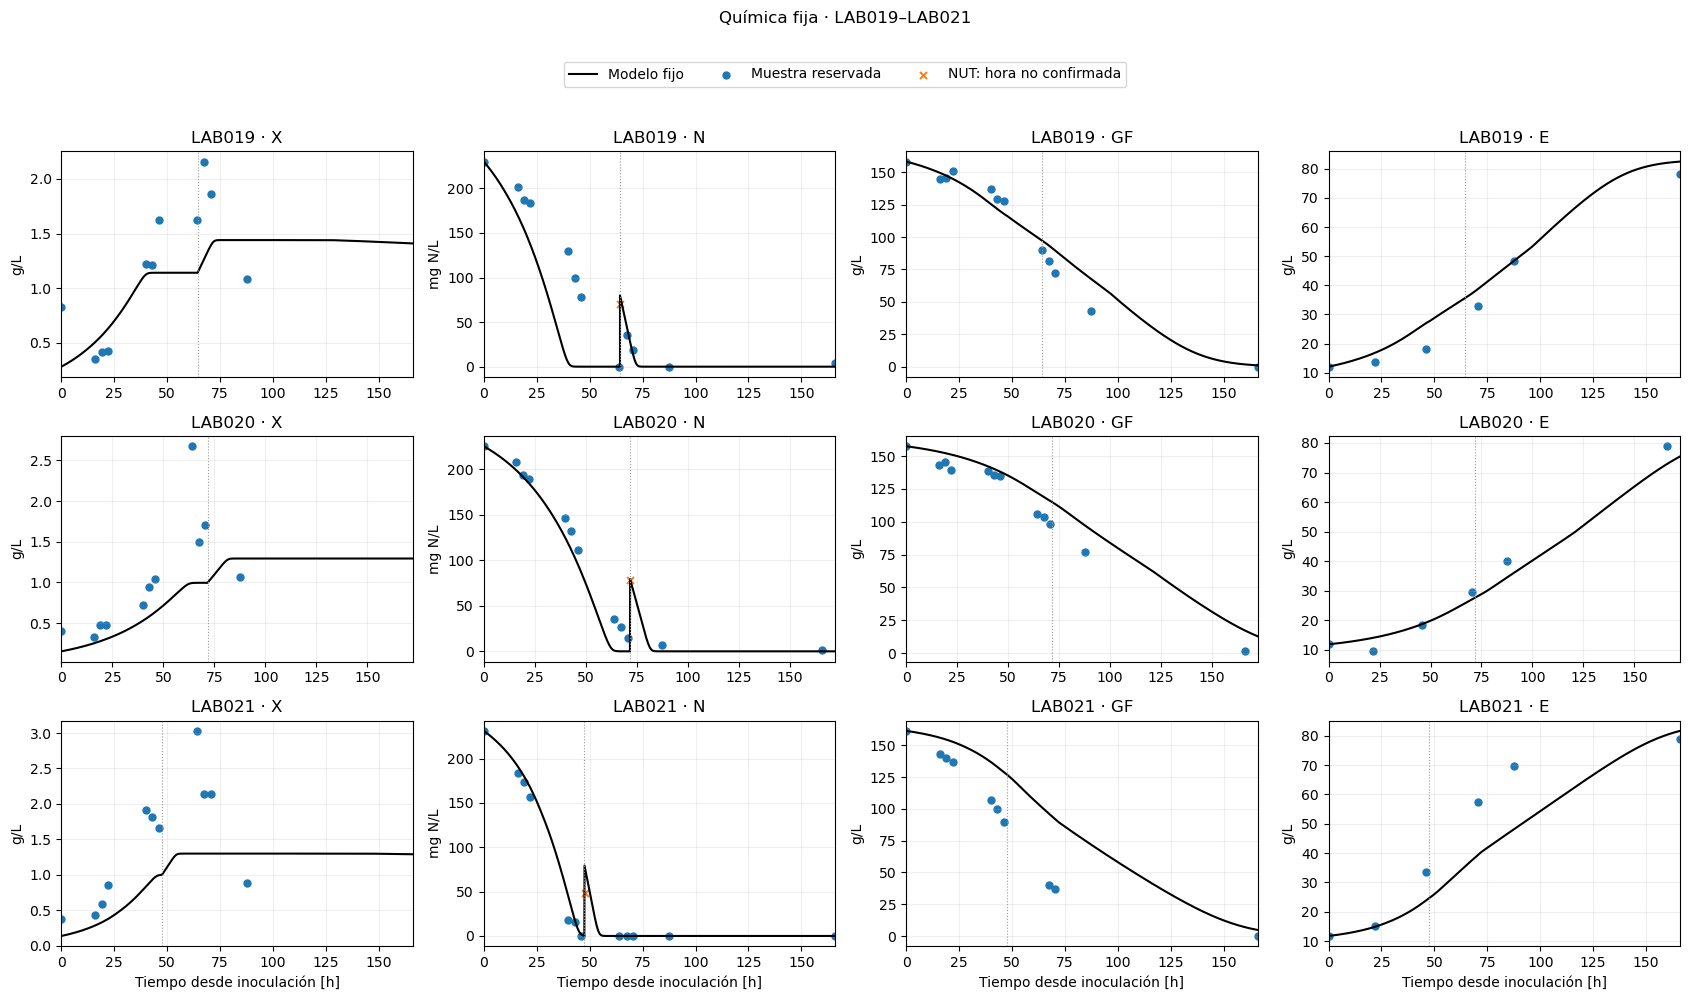

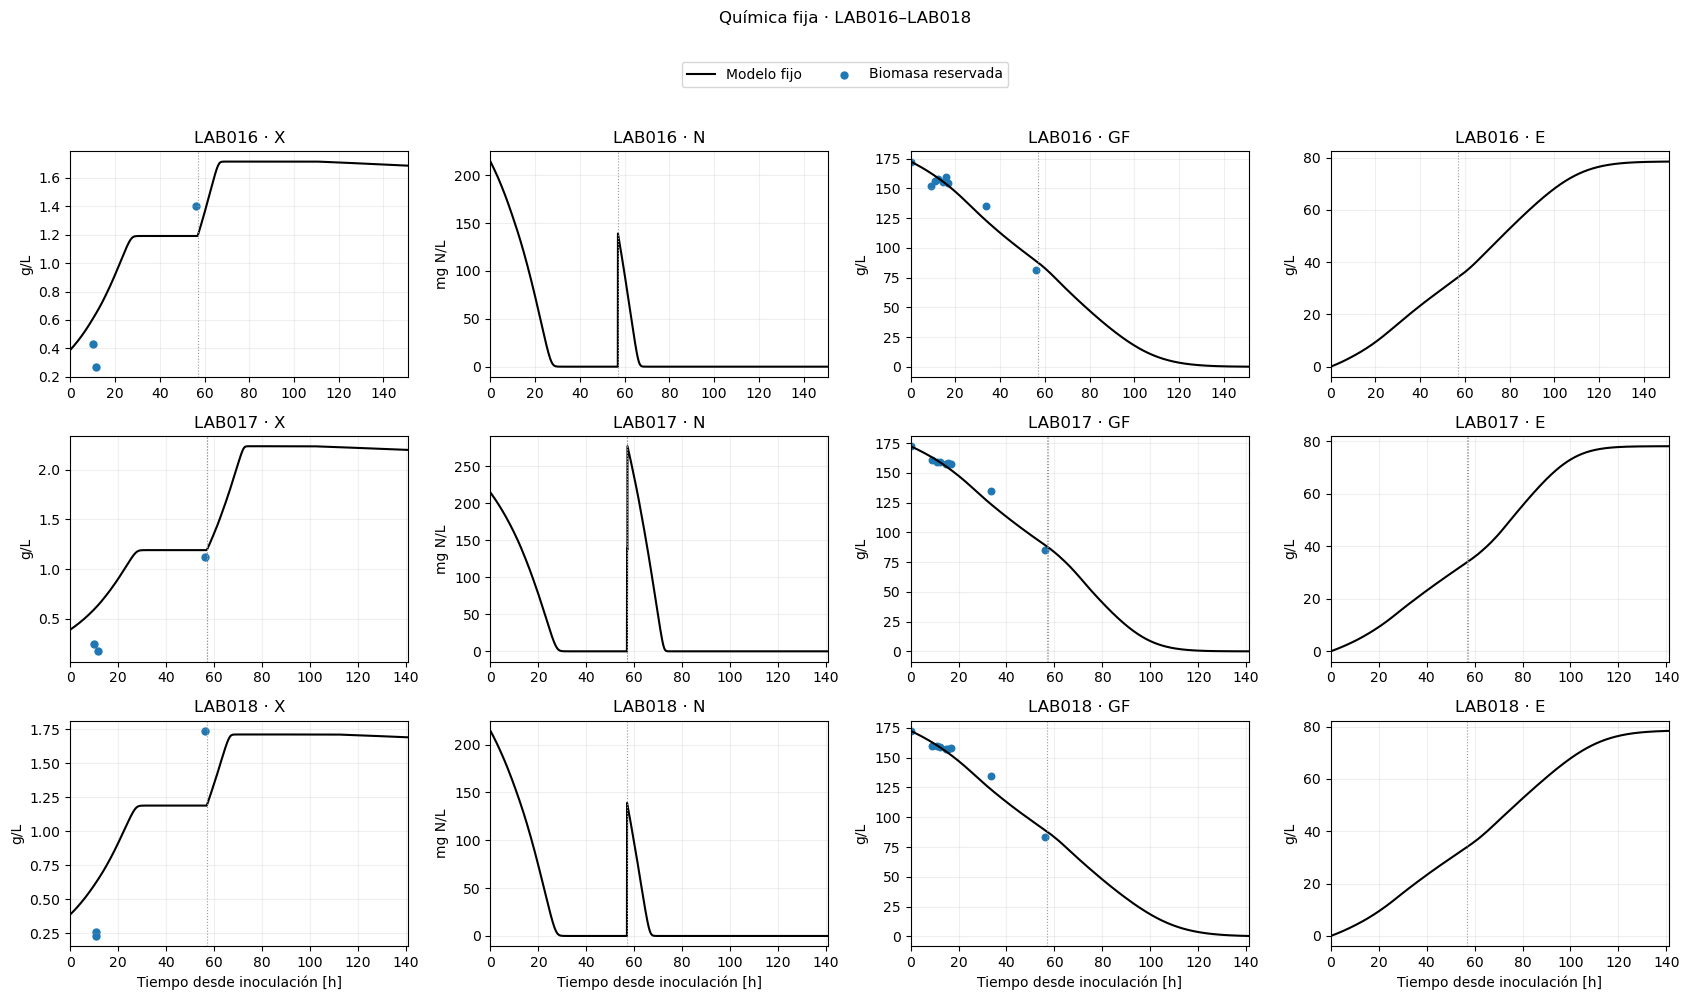

In [5]:
for cohort in (LABS[3:],LABS[:3]):
    fig,axs=plt.subplots(3,4,figsize=(17,10),sharex='row')
    for i,lab in enumerate(cohort):
        cr=V.cores['theta_full',lab];end=V.horizons[lab];cr=cr[cr.index<=end]
        for j,(ch,col,mult,unit) in enumerate([('X','X_viable_g_l',1.,'g/L'),('N','YAN_mg_l',1000.,'mg N/L'),('GF','GF_g_l',1.,'g/L'),('E','E_g_l',1.,'g/L')]):
            ax=axs[i,j];ax.plot(cr.index,cr[ch]*mult,c='black',lw=1.5,label='Modelo fijo')
            if lab in LABS[3:]:
                pts=V.chem[V.chem.lab.eq(lab)]
                if col in pts:
                    for nut,marker,label in [(False,'o','Muestra reservada'),(True,'x','NUT: hora no confirmada')]:
                        p=pts[pts.is_NUT.eq(nut)][['t_h',col]].dropna()
                        ax.scatter(p.t_h,p[col],s=25,marker=marker,label=label)
            elif ch=='X':
                p=V.biomass[V.biomass.lab.eq(lab)]
                ax.scatter(p.t_h,p.X_viable_g_l,s=25,label='Biomasa reservada')
            elif ch=='GF':
                p=V.density[V.density.lab.eq(lab)]
                # Column is resolved from the stored density calibration table.
                candidates=[c for c in p if c in ('GF_density_g_l','sugar_density_g_l','GF_from_density_g_l','sugar_g_l','GF_g_l')]
                if candidates:ax.scatter(p.t_h,p[candidates[0]],s=22,label='Azúcar por densidad')
            for t,d in V.cache['theta_full',lab]['events']:ax.axvline(t,c='.6',ls=':',lw=.8)
            ax.set(xlim=(0,end),title=f'{lab} · {ch}',ylabel=unit);ax.grid(alpha=.2)
            if i==2:ax.set_xlabel('Tiempo desde inoculación [h]')
    handles,labels=axs[0,0].get_legend_handles_labels()
    fig.legend(handles,labels,loc='upper center',ncol=3)
    fig.suptitle('Química fija · '+'–'.join((cohort[0],cohort[-1])),y=.99)
    show(fig)

## Recalibración Z1/Z2

Se conserva la organización de v3: primero el ajuste conjunto de los seis LAB (`joint`), después la transferencia entre corridas (`transfer`). En `transfer`, LAB016–018 se predicen con parámetros ajustados en LAB019–021, y LAB019–021 con parámetros ajustados en LAB016–018. El ajuste conjunto es descriptivo; no constituye validación externa. Se mantiene `theta_full` fijo y se usan tres inicializaciones para Z2, con los mismos límites de v3.

In [6]:
GROUPS={'all_six':LABS,'train_019_021':LABS[3:],'train_016_018':LABS[:3]}
for label,training in GROUPS.items():
    V.fit_layer('theta_full',training,label)
    pd.DataFrame(V.fit_table).to_csv(OUT/'fit_parameters.csv',index=False)
FIT_TABLE=pd.DataFrame(V.fit_table)
display(FIT_TABLE[['training','stage',*GAS_NAMES,'objective','success','active_bounds','jacobian_ratio']])
METRICS=[];CURVES=[]
for training in GROUPS:
    for stage in ('Z1','Z2'):
        params=V.v3_fits[('reference_20_45',PRIMARY,'woO2','theta_full',training,stage)]
        m=V.metrics_v3('theta_full',params,LABS).assign(training=training,stage=stage)
        m['role']=['calibration' if lab in GROUPS[training] else 'validation' for lab in m.lab]
        METRICS.append(m)
        for lab in LABS:
            cr=V.curve_v3('theta_full',lab,params)
            CURVES.append(cr[cr.t_h<=V.horizons[lab]+1e-8].assign(lab=lab,training=training,stage=stage))
METRICS=pd.concat(METRICS,ignore_index=True);CURVES=pd.concat(CURVES,ignore_index=True)
display(METRICS.query('window=="all"').groupby(['training','stage','role']).RMSE.mean().to_frame())

reference_20_45 offline_30min woO2 theta_full all_six Z1/Z2 0.140179 0.116715


reference_20_45 offline_30min woO2 theta_full train_019_021 Z1/Z2 0.056998 0.056319


reference_20_45 offline_30min woO2 theta_full train_016_018 Z1/Z2 0.076658 0.04321


,training,stage,kCO2_release_h,CO2sat_scale,matrix_gain,objective,success,active_bounds,jacobian_ratio
0,all_six,Z1,0.424588,0.351390,0.895553,0.140179,True,,NaN
1,all_six,Z2,0.166900,2.496947,0.938551,0.116715,True,CO2sat_scale,0.001676
2,train_019_021,Z1,0.424588,0.351390,1.038403,0.056998,True,,NaN
3,train_019_021,Z2,1.418606,2.122002,1.038625,0.056319,True,,0.000187
4,train_016_018,Z1,0.424588,0.351390,0.847774,0.076658,True,,NaN
5,train_016_018,Z2,0.118058,2.500000,0.918720,0.043210,True,CO2sat_scale,0.016025


RMSE
training      stage role                 
all_six       Z1    calibration  0.151726
              Z2    calibration  0.135586
train_016_018 Z1    calibration  0.160819
                    validation   0.144645
              Z2    calibration  0.120069
                    validation   0.153184
train_019_021 Z1    calibration  0.137815
                    validation   0.185881
              Z2    calibration  0.137506
                    validation   0.193631

## CO₂: ajuste conjunto y transferencia

Misma organización que v3, con `theta_full` fijo: **joint** muestra el ajuste con los seis LAB; **transfer** reúne las dos direcciones de transferencia en una sola figura. La fila superior contiene LAB016–018 y la inferior LAB019–021. Se conservan la señal densa válida, las medianas usadas, Z1/Z2, las marcas de nutrición y las curvas completas en un eje temporal común.

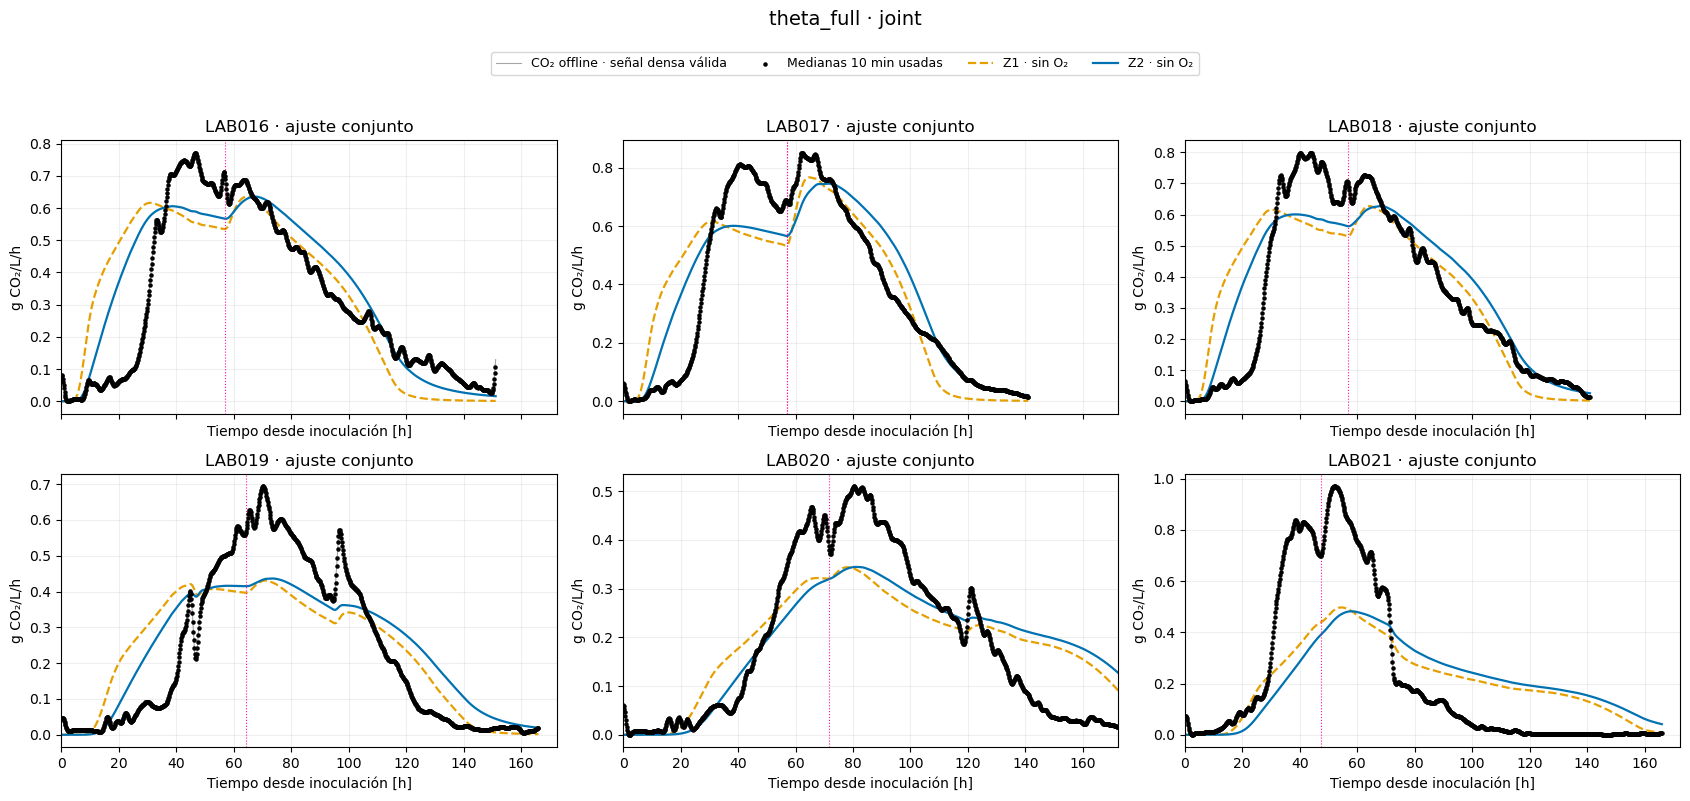

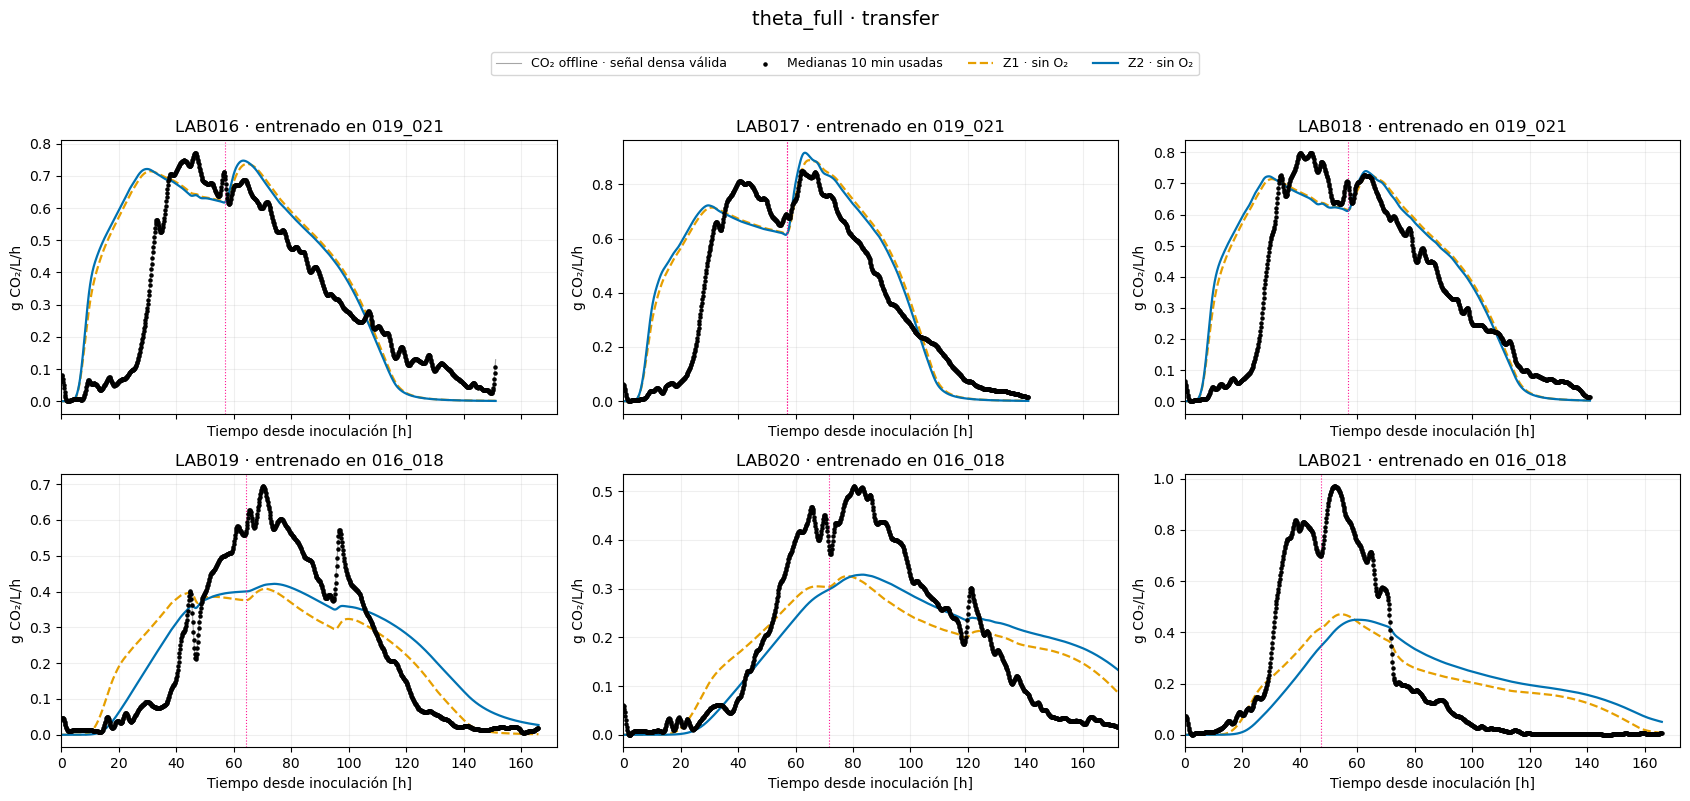

In [7]:
case='theta_full'
for kind in ('joint','transfer'):
    fig,axs=plt.subplots(2,3,figsize=(17,8),sharex='col')
    for ax,lab in zip(axs.flat,LABS):
        training='all_six' if kind=='joint' else 'train_019_021' if lab in LABS[:3] else 'train_016_018'
        dense=V.dense[lab];keep=dense.time_h.between(0.,V.horizons[lab])
        ax.plot(dense.time_h[keep],np.where(dense.valid_for_fit,dense[PRIMARY],np.nan)[keep],c='0.65',lw=.8,label='CO₂ offline · señal densa válida')
        obs=V.observations[PRIMARY,lab]
        ax.scatter(obs.t_h,obs.y,c='black',s=5,label='Medianas 10 min usadas',zorder=5)
        for stage,color,style in [('Z1','#E69F00','--'),('Z2','#0072B2','-')]:
            curve=CURVES.query('lab == @lab and training == @training and stage == @stage')
            ax.plot(curve.t_h,curve.CO2_observed_operator,c=color,ls=style,lw=1.6,label=stage+' · sin O₂')
        for t,dose in V.batches[lab].pulses['N']:ax.axvline(t,c='deeppink',ls=':',lw=.8)
        ax.set(title=f'{lab} · '+('ajuste conjunto' if kind=='joint' else f'entrenado en {training[6:]}'),
               xlabel='Tiempo desde inoculación [h]',ylabel='g CO₂/L/h',xlim=(0.,max(V.horizons.values())))
        ax.grid(alpha=.2)
    fig.legend(*axs[0,0].get_legend_handles_labels(),loc='upper center',ncol=4,fontsize=9)
    fig.suptitle(case+' · '+kind,y=.995,fontsize=14)
    show(fig)

## Fuente, liberación y acumulación
Se muestran por separado las tasas y el inventario disuelto del Z2 entrenado en LAB019–021. El CO₂ disuelto no se ha medido: es una predicción del modelo, no una validación de solubilidad.

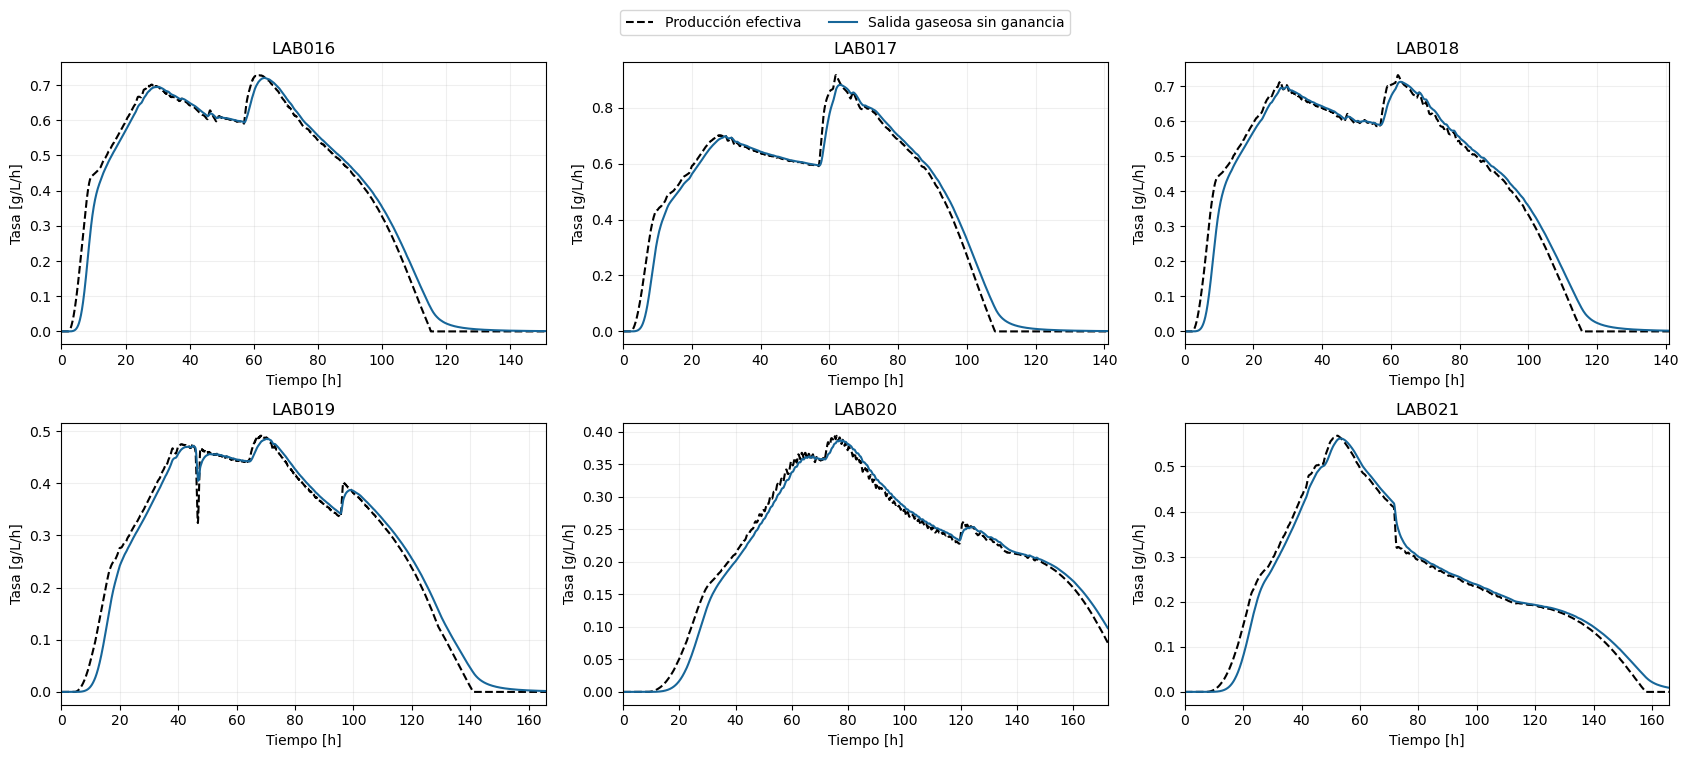

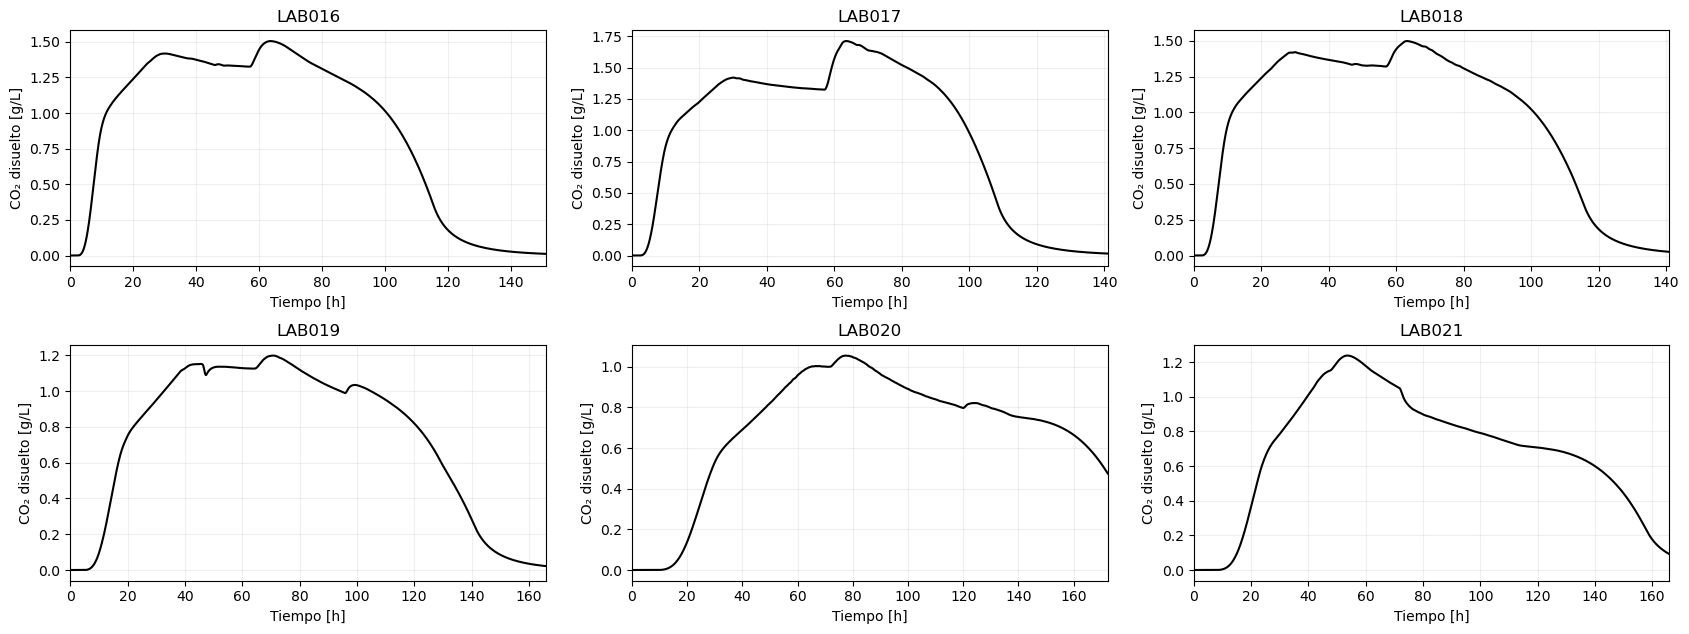

In [8]:
fig,axs=plt.subplots(2,3,figsize=(17,8))
for ax,lab in zip(axs.flat,LABS):
    cr=CURVES.query('lab==@lab and training=="train_019_021" and stage=="Z2"')
    ax.plot(cr.t_h,cr.qprod,c='black',ls='--',label='Producción efectiva')
    ax.plot(cr.t_h,cr.qgas,c='#176699',label='Salida gaseosa sin ganancia')
    ax.set(title=lab,xlim=(0,V.horizons[lab]),xlabel='Tiempo [h]',ylabel='Tasa [g/L/h]');ax.grid(alpha=.2)
h,l=axs[0,0].get_legend_handles_labels();fig.legend(h,l,loc='upper center',ncol=2);show(fig)
fig,axs=plt.subplots(2,3,figsize=(17,7))
for ax,lab in zip(axs.flat,LABS):
    cr=CURVES.query('lab==@lab and training=="train_019_021" and stage=="Z2"')
    ax.plot(cr.t_h,cr.Cd,c='black')
    ax.set(title=lab,xlim=(0,V.horizons[lab]),xlabel='Tiempo [h]',ylabel='CO₂ disuelto [g/L]');ax.grid(alpha=.2)
show(fig)

## Comparación con v3 sobre los mismos datos y verificaciones
Se comprueba igualdad de las observaciones y de las trayectorias químicas con v3. La comparación de RMSE utiliza las mismas muestras de CO₂ y el mismo operador, con parámetros recalibrados en cada formulación. No implica que toda diferencia sea atribuible a una constante física identificada.

In [9]:
PRIOR=FM/'laboratory_2026/notebooks/diagnostics/co2_lab016_021_recalibration_v3_artifacts'
old_obs=pd.read_csv(PRIOR/'observations_10min.csv')
OBS=pd.concat([V.observations[PRIMARY,lab] for lab in LABS],ignore_index=True)
old=old_obs[old_obs.filtering.eq(PRIMARY)].sort_values(['lab','t_h'])
now=OBS.sort_values(['lab','t_h'])
assert list(old.lab)==list(now.lab)
assert np.max(abs(old.t_h.to_numpy()-now.t_h.to_numpy()))<1e-8
assert np.max(abs(old.y.to_numpy()-now.y.to_numpy()))<1e-10
prior_metrics=pd.read_csv(PRIOR/'metrics.csv')
prior_metrics=prior_metrics.query('theta=="theta_full" and source=="v3_fit" and window=="all"')
comparison=METRICS.query('window=="all"').merge(prior_metrics[['lab','training','stage','RMSE']],on=['lab','training','stage'],suffixes=('_woO2','_v3'))
comparison['delta_RMSE']=comparison.RMSE_woO2-comparison.RMSE_v3
display(comparison.query('training=="train_019_021"')[['lab','role','stage','RMSE_v3','RMSE_woO2','delta_RMSE']].round(5))
prior_chem=pd.read_csv(PRIOR/'chemistry_trajectories.csv')
CHEM_PARITY=[]
for lab in LABS:
    old=prior_chem.query('theta=="theta_full" and temperature=="reference_20_45" and lab==@lab')
    cr=V.cores['theta_full',lab]
    assert np.max(abs(old.t_h.to_numpy()-cr.index.to_numpy()[:len(old)]))<1e-8
    err=float(np.max(abs(old[list(CORE_STATES)].to_numpy()-cr[list(CORE_STATES)].iloc[:len(old)].to_numpy())))
    CHEM_PARITY.append(dict(lab=lab,max_absolute_difference=err))
assert max(r['max_absolute_difference'] for r in CHEM_PARITY)<1e-4
NUMERICAL=[]
for training in GROUPS:
    for stage in ('Z1','Z2'):
        p=V.v3_fits[('reference_20_45',PRIMARY,'woO2','theta_full',training,stage)]
        for lab in LABS:
            c=V.cache['theta_full',lab]
            y,physical,cd,qgas=V.observed_prediction('theta_full',lab,p)
            balance=float(np.max(abs(np.diff(cd)-c['dt']*(c['source'][:-1]-qgas[1:]))))
            assert balance<1e-10 and min(cd.min(),physical.min(),c['source'].min())>=-1e-12
            row=dict(training=training,stage=stage,lab=lab,balance=balance)
            if training=='train_019_021' and stage=='Z2':
                fine=V.observed_prediction('theta_full',lab,p,max_step=1./48.)[0]
                o=V.observations[PRIMARY,lab];t=V.dense[lab].time_h
                difference=np.interp(o.t_h,t,y)-np.interp(o.t_h,t,fine)
                row['refinement_max']=float(np.max(abs(difference)))
                assert row['refinement_max']<.025
            NUMERICAL.append(row)
assert FIT_TABLE.success.all()
assert V.verify_protected()>0
display(pd.DataFrame(CHEM_PARITY));display(pd.DataFrame(NUMERICAL).groupby(['training','stage']).max(numeric_only=True))
for name,df in [('fit_parameters',FIT_TABLE),('optimizer_runs',pd.DataFrame(V.fit_runs)),('metrics',METRICS),
                ('gas_trajectories',CURVES),('observations_10min',OBS),('coverage',V.coverage),
                ('initial_conditions',V.initials.reset_index()),('chemistry_metrics',V.chemistry_v3('theta_full')),
                ('comparison_v3',comparison),('numerical_checks',pd.DataFrame(NUMERICAL)),('chemistry_parity',pd.DataFrame(CHEM_PARITY))]:
    df.to_csv(OUT/(name+'.csv'),index=False)
pd.concat([cr[cr.index<=V.horizons[lab]].rename_axis('t_h').reset_index().assign(lab=lab) for (case,lab),cr in V.cores.items()],ignore_index=True).to_csv(OUT/'chemistry_trajectories.csv',index=False)
display(Markdown('**Resultado principal calculado:**'))
for stage in ('Z1','Z2'):
    for role in ('calibration','validation'):
        m=comparison.query('training=="train_019_021" and stage==@stage and role==@role')
        display(Markdown(f'{stage}, {role}: RMSE medio sin O₂ **{m.RMSE_woO2.mean():.4f}**; v3 con O₂ **{m.RMSE_v3.mean():.4f}** g/L/h.'))
display(Markdown('La cinética química no se ha ajustado. Persistir un error de azúcar o etanol requiere revisar esa cinética o sus entradas; la ganancia de CO₂ no corrige esas trayectorias. Los límites activos y la transferencia determinan el alcance del ajuste.'))
TRACEABILITY=dict(created_at=datetime.now().astimezone().isoformat(),python=sys.executable,
    source_sha256=sha256(ND/'co2_woO2.source.ipynb'),theta_fixed=V.theta_snapshot,
    oxygen_state=False,oxygen_factor=False,chemical_states=CORE_STATES,gas_state='Cd',
    source='principal v3 source without oxygen modulation; all other source terms fixed',
    primary_filter=PRIMARY,temperature='reference_20_45',main_training=LABS[3:],main_validation=LABS[:3],
    protected_input_sha256=V.protected,figures_inline=FIGURES,elapsed_seconds=time.perf_counter()-START)
display(JSON(TRACEABILITY,expanded=False))
print('Verificación completada. Tiempo [s]:',round(time.perf_counter()-START,1))

,lab,role,stage,RMSE_v3,RMSE_woO2,delta_RMSE
12,LAB016,validation,Z1,0.17711,0.19633,0.01922
13,LAB017,validation,Z1,0.15792,0.18137,0.02344
14,LAB018,validation,Z1,0.15529,0.17995,0.02466
15,LAB019,calibration,Z1,0.12528,0.13179,0.00650
16,LAB020,calibration,Z1,0.08597,0.08998,0.00401
17,LAB021,calibration,Z1,0.19436,0.19168,-0.00269
18,LAB016,validation,Z2,0.19151,0.20399,0.01248
19,LAB017,validation,Z2,0.17257,0.18877,0.01620
20,LAB018,validation,Z2,0.17069,0.18813,0.01744
21,LAB019,calibration,Z2,0.13073,0.13451,0.00378


,lab,max_absolute_difference
0,LAB016,0.000005
1,LAB017,0.000006
2,LAB018,0.000020
3,LAB019,0.000054
4,LAB020,0.000020
5,LAB021,0.000005


balance  refinement_max
training      stage                              
all_six       Z1     2.293088e-16             NaN
              Z2     4.497271e-16             NaN
train_016_018 Z1     2.293088e-16             NaN
              Z2     8.933826e-16             NaN
train_019_021 Z1     2.293088e-16             NaN
              Z2     1.188286e-16        0.001463

**Resultado principal calculado:**

Z1, calibration: RMSE medio sin O₂ **0.1378**; v3 con O₂ **0.1352** g/L/h.

...

Z2, calibration: RMSE medio sin O₂ **0.1375**; v3 con O₂ **0.1342** g/L/h.

Z2, validation: RMSE medio sin O₂ **0.1936**; v3 con O₂ **0.1783** g/L/h.

La cinética química no se ha ajustado. Persistir un error de azúcar o etanol requiere revisar esa cinética o sus entradas; la ganancia de CO₂ no corrige esas trayectorias. Los límites activos y la transferencia determinan el alcance del ajuste.

<IPython.core.display.JSON object>

Verificación completada. Tiempo [s]: 67.4
